In [2]:
# Origin: https://github.com/SiyuanYan1/Derm1M
!nvidia-smi

Mon Oct 19 09:48:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H100 PCIe               On  |   00000000:B5:00.0 Off |                    0 |
| N/A   55C    P0            102W /  350W |   54833MiB /  81559MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
from PIL import Image
import torch
from torch import nn
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode # original https://github.com/mlfoundations/open_clip (not for this code)

In [4]:
import sys
import os

os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Adds the 'src' directory to the path so you can import its subfolders directly
sys.path.append(os.path.abspath("src"))
sys.path.append(os.path.abspath("script"))
path_to_root = os.path.abspath(os.path.join('..'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

In [5]:
# Augmentation Scheme Loop
import Datasets.MILK_10K.augmentation_scheme_image
import importlib
importlib.reload(Datasets.MILK_10K.augmentation_scheme_image)

from Datasets.MILK_10K.augmentation_scheme_image import _augmentation_gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
# original https://github.com/mlfoundations/open_clip (not for this code)
import CAE
from src import open_clip # super important line as we are replaceing older open_clip

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


In [5]:
# required for CPCC model 

dataset_name = "../Datasets/MILK_10K" # give the correct directory

import importlib
import Datasets.hierarchy_data.data_hierarchy as dh
import Datasets.hierarchy_data.cpcc_losses as CPloss
importlib.reload(CPloss)
importlib.reload(dh)

CPCCLoss = CPloss.CPCCLoss

In [6]:
# getting the fine tuned model
import script.custom_models.derm1M_custom_classifier
import importlib
from geom_hyp import lorentz as L
from geom_hyp import manifold_conversion as MC
importlib.reload(script.custom_models.derm1M_custom_classifier)
from script.custom_models.derm1M_custom_classifier import DermLIPWithHead, DermLIPWithHypHead, DermLIPWithHead_CPCC

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


In [6]:
ls ../../../../../projects/academic/sangst/zahidhas/Model_Weights/Derm1M/

DermLIP_CPCC_head_clinical_dermoscopic.pth
DermLIP_CPCC_head_clinical_dermoscopic_new.pth
DermLIP_clf_head_clinical_dermoscopic.pth
DermLIP_clf_head_clinical_only.pth
DermLIP_clf_head_dermoscopic_only.pth
DermLIP_head_clinical_dermoscopic_weight.pth
DermLIP_hyper_head_clinical_dermoscopic_weight.pth
DermLIP_hyper_learn_head_64_Derm12345_weight.pth
DermLIP_hyper_learn_head_64_Derm12345_weight_ce.pth
DermLIP_hyper_learn_head_64_ISIC2019_weight_ce.pth
DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer.pth
DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_noCE.pth
DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius.pth
DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_2.pth
DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_3.pth
DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_3_fp32.pth
DermLIP_hyper_sarkar_head_64_ISIC2019_weight_ce.pth
DermLIP_hyper_sarkar_head_64_ISIC2019_weigh

In [32]:
# model manual checking 
print("hyperbolic head model")
results = torch.load("../Datasets/sarker_embeddingDerm12345 datasets_64_small_radius.pt")
z_p = results["data"]  # torch.Tensor
z_l = MC.poincare_to_lorentz(z_p) # lorentz points
# data loader 
mul_factor = 3.0
z_l = L.exp_map0(L.log_map0(z_l[:, 1:]) * mul_factor)

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = DermLIPWithHypHead(64, l_target= z_l[0:40,:].to(device), multilayer= True) # lorentz space components
# model = DermLIPWithHead(11) # Euclidean model
# Weight loading
# PATH = 'weights_local/DermLIP_hyper_head_clinical_dermoscopic_weight.pth'
PATH = '../../../../../projects/academic/sangst/zahidhas/Model_Weights/Derm1M/DermLIP_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_3_fp32.pth'
checkpoint = torch.load(PATH, map_location=device)
missing, unexpected = model.load_state_dict(checkpoint['model_state_dict'],  strict=False)
print(f"Missing: {missing}")
print(f"Unexpected: {unexpected}")

hyperbolic head model


/scratch/26547344/ipykernel_704657/1740233564.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  results = torch.load("../Datasets/sarker_embeddingDerm12345 datasets_64_sma

Missing: []
Unexpected: []


In [7]:
# required for CPCC model 

data_hierarchy= dh.Hierarchy_W(dataset_name, "") 
from types import SimpleNamespace

args = SimpleNamespace(
    cpcc=1,
    cpcc_metric="lorentz_mean",   # "l2", "l1", "poincare", or "poincare_exp_c", poincare_mean, lorentz_mean
    leaf_only=0,
    lamb=1.0,
    center=0,

    poincare_low_dim_project=0,
    poincare_head_dim=512,
    hyp_c=1.0,
    clip_r=2.3,
    train_c=False,
    feature_dim=512,

    num_workers=12,
    batch_size=512,
    seeds=5,

    warm=False,
    temp=0.1,
    normalize=0,

    bottleneck=True,
    augment=True,
    local_rank=0,
    encoder_manifold="euclidean",
)

criterion_cpcc = CPCCLoss(data_hierarchy, args)

model = DermLIPWithHead_CPCC(11, criterion_cpcc = criterion_cpcc)


# Weight loading
PATH = 'weights_local/DermLIP_CPCC_head_clinical_dermoscopic.pth'

state_dict = torch.load(PATH, map_location=device)['model_state_dict']
missing, unexpected = model.load_state_dict(state_dict, strict=False)
print(f"Missing: {missing}")
print(f"Unexpected: {unexpected}")

NameError: name 'dh' is not defined

In [7]:
# same vision model as the panderm model! this is awesome!
# https://huggingface.co/redlessone/DermLIP_PanDerm-base-w-PubMed-256/blob/b079489efd7ec1f8f9c5553c117ab8d4335f99c3/README.md
model, _, preprocess = open_clip.create_model_and_transforms('hf-hub:redlessone/DermLIP_PanDerm-base-w-PubMed-256')
model.eval()

# Text tokenizer
tokenizer = open_clip.get_tokenizer('hf-hub:redlessone/DermLIP_PanDerm-base-w-PubMed-256')


print('DONE')

NameError: name 'open_clip' is not defined

In [6]:
#load and save from local if ever required!
# torch.save(model.state_dict(), "weights_local/panderm_mm.pth")
#just define the model: You Know How
#model.load_state_dict(torch.load("model_weights.pth", weights_only=True))

In [7]:
# clip style model: inspect the open_clip for details.
# https://huggingface.co/redlessone/DermLIP_ViT-B-16
model, _, preprocess = open_clip.create_model_and_transforms(
    'hf-hub:redlessone/DermLIP_ViT-B-16')

# Initialize tokenizer
tokenizer = open_clip.get_tokenizer('hf-hub:redlessone/DermLIP_ViT-B-16')
model.eval()

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768,), eps=1e-05, elementwise_affine

In [6]:
#load and save from local if ever required!

# torch.save(model.state_dict(), "weights_local/clip_vit.pth")
#just define the model: YKH
#model.load_state_dict(torch.load("model_weights.pth", weights_only=True))


In [8]:
# data loading. 

import sys, importlib
path_to_root = os.path.abspath(os.path.join('..'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

import Datasets.MILK_10K.Milk10_dataset_loader 
import Datasets.isic_kaggle_2016.IsicKaggle2016
import Datasets.fitzpatrick17k.fitzpatrick_data_loader

importlib.reload(Datasets.MILK_10K.Milk10_dataset_loader)

from Datasets.MILK_10K.Milk10_dataset_loader import MILK10kDataset, get_image_transform
from Datasets.isic_kaggle_2016.IsicKaggle2016 import TumorDataset
from Datasets.fitzpatrick17k.fitzpatrick_data_loader import Fitz17kDataset

# Derm12345 loading

path_to_root = os.path.abspath(os.path.join('../../../../../projects/academic/sangst/zahidhas/Datasets'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

from DERM12345.derm12345_data_loader import DERM12345Dataset


# ISIC loading
from isic_2019.isic_2016_dataset_loader import ISIC2019Dataset


In [9]:
im_size = 224

transform_train_no_np = transforms.Compose([
    transforms.Resize((im_size, im_size),  interpolation=InterpolationMode.BICUBIC),  # Resize the image
    transforms.PILToTensor()  # Convert to uint8 tensor array [c, h, w]
])

In [11]:
# ISIC 2019 datasets
root = "../../../../../projects/academic/sangst/zahidhas/Datasets/isic_2019"

dataset_keep_track = "Isic2019 datasets"

img_size = 224

train_dataset = ISIC2019Dataset(
    root=root,
    split="test",
    image_transform=get_image_transform('train', img_size=img_size),
    balanced=False,
    seed=44,
)

In [11]:
# Derm12345 dataset
dataset_keep_track = "Derm12345 datasets"
print(dataset_keep_track)

root             = "../../../../../projects/academic/sangst/zahidhas/Datasets/DERM12345/"

img_size = 224

train_dataset  = DERM12345Dataset(
        root=root,
        split="test",
        image_transform=get_image_transform("train", img_size = img_size),
        target_col="label",
        balanced=False,
        seed=44,
    )

Derm12345 datasets


In [111]:
# MILK 10K dataset
dataset_keep_track = "MILK 10K datasets"
print(dataset_keep_track)

root             = '../Datasets/MILK_10K/Train' # /Train or /Test
split            = 'train'

train_dataset =  MILK10kDataset(
        root             = root, 
        split            = split,
        image_transform  = get_image_transform(split, im_size),
        balanced         = False,
        seed             = 44,)

MILK 10K datasets


In [11]:
import matplotlib.pyplot as plt
plt.imshow(im['clinical_closeup'][2].numpy())

NameError: name 'im' is not defined

In [ ]:
# FitzPatrick dataset
dataset_keep_track = "Fitzpatrick datasets"
print(dataset_keep_track)

root             = '../Datasets/fitzpatrick17k/'
csv_file = "fitzpatrick17k.csv"

img_size = 224

train_dataset =  Fitz17kDataset(
        root             = root,
        csv_file         = csv_file,
        image_transform  = get_image_transform("train", img_size),
    )

In [16]:
# ISIC 2016 datasets
dataset_keep_track = "ISIC 2016 datasets"
print(dataset_keep_track)
root = "../Datasets/isic_kaggle_2016/Preprocessed_Data"
train_dataset = TumorDataset(root, "train", transform=transform_train_no_np)

ISIC 2016 datasets


In [12]:
# common path begins HERE
print(dataset_keep_track)
im, label = train_dataset[0]

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,persistent_workers=False,
)

Isic2019 datasets


In [13]:
len(train_loader)

258

In [14]:
#%% iteration over the dataset
print(dataset_keep_track)

loader_iter = iter(train_loader)
images, labels = next(loader_iter)

Isic2019 datasets


In [15]:
constants_zoo = {
    'imagenet': {'mean': (0.485, 0.456, 0.406), 'std': (0.228, 0.224, 0.225)},
    'openai_clip':{'mean': (0.48145466, 0.4578275, 0.40821073), 'std': (0.26862954, 0.26130258, 0.27577711)},
    'uniform': {'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5)}
}
constants = constants_zoo['openai_clip']

mean, std = constants.get('mean'), constants.get('std')
dl_preprocess = transforms.Compose([
    transforms.Normalize(mean=mean, 
                         std=std),
])

In [16]:
loader_iter = iter(train_loader)
images, labels = next(loader_iter)

if dataset_keep_track == "MILK 10K datasets":
    type_image = images['dermoscopic']
    input_image = dl_preprocess(type_image/255.0)
    print(dataset_keep_track)
elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets', "Derm12345 datasets", "Isic2019 datasets"]:
    type_image = images
    input_image = dl_preprocess(type_image/255.0)
    print(dataset_keep_track)

Isic2019 datasets


In [17]:
type_image.shape

torch.Size([32, 3, 224, 224])

In [33]:
# Panderm Vision Transformer model.
# inside the model: https://github.com/SiyuanYan1/Derm1M/blob/main/src/CAE/models/modeling_finetune.py
# text encodeing: https://huggingface.co/redlessone/DermLIP_PanDerm-base-w-PubMed-256
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = model.to(device)
model.eval()
    
print("Panderm VIT ONLY")
print(dataset_keep_track)

for _ in range(1):

    images, labels = next(loader_iter)

    if dataset_keep_track == "MILK 10K datasets":
        type_image = images['dermoscopic']
    elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets', "Derm12345 datasets", "Isic2019 datasets"]:
        type_image = images

    
    input_image = dl_preprocess(type_image/255.0)
    input_image = input_image.to(device)
    
    with torch.no_grad():
        # o = model.encode_image(input_image)
        o = model.visual(input_image)
        
        oupt_list, labs1 = [], []
        labs2 = []
        oupt_list.append(o.cpu())
        # labs1.append(labels['metadata']['dermoscopic_image_type'])
        labs2.append(labels['class_index'])


        x = model.visual.patch_embed(input_image)
        batch_size, seq_len, _ = x.size()

        cls_tokens = model.visual.cls_token.expand(batch_size, -1, -1)  # stole cls_tokens impl from Phil Wang, thanks
        x = torch.cat((cls_tokens, x), dim=1)
        if model.visual.pos_embed is not None:
            x = x + model.visual.pos_embed.expand(batch_size, -1, -1).type_as(x).to(x.device).clone().detach()

        x = model.visual.pos_drop(x)

        rel_pos_bias = model.visual.rel_pos_bias() if model.visual.rel_pos_bias is not None else None
        i = 0
        for blk in model.visual.blocks[0:-1]:
            x = blk(x, rel_pos_bias=rel_pos_bias)

            print(i)
            i += 1
        # got the final attention stage (find the attention map)
        blk = model.visual.blocks[-1]
        # blk attn start.  blk.attn(blk.norm1(x), rel_pos_bias=rel_pos_bias) equvalence
        fin_attn = blk.attn
        x1 = blk.norm1(x)

        B, N, C = x1.shape
        qkv_bias = None
        if fin_attn.q_bias is not None:
            qkv_bias = torch.cat((fin_attn.q_bias, torch.zeros_like(fin_attn.v_bias, requires_grad=False), fin_attn.v_bias))
        qkv = F.linear(input=x1, weight=fin_attn.qkv.weight, bias=qkv_bias)
        qkv = qkv.reshape(B, N, 3, fin_attn.num_heads, -1).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]   # make torchscript happy (cannot use tensor as tuple)

        q = q * fin_attn.scale
        attn = (q @ k.transpose(-2, -1))

        if fin_attn.relative_position_bias_table is not None:
            relative_position_bias = \
                fin_attn.relative_position_bias_table[fin_attn.relative_position_index.view(-1)].view(
                    fin_attn.window_size[0] * fin_attn.window_size[1] + 1,
                    fin_attn.window_size[0] * fin_attn.window_size[1] + 1, -1)  # Wh*Ww,Wh*Ww,nH
            relative_position_bias = relative_position_bias.permute(2, 0, 1).contiguous()  # nH, Wh*Ww, Wh*Ww
            attn = attn + relative_position_bias.unsqueeze(0)
        if rel_pos_bias is not None:
            attn = attn + rel_pos_bias
        attn = attn.softmax(dim=-1)
        attn = fin_attn.attn_drop(attn)
        x1 = (attn @ v).transpose(1, 2).reshape(B, N, -1)
        x1 = fin_attn.proj(x1)
        x1 = fin_attn.proj_drop(x1)
        ## blk attn end
        # equ
        x = x + blk.drop_path(blk.gamma_1 * x1) # x1 = blk.attn(blk.norm1(x), rel_pos_bias=rel_pos_bias)
        x = x + blk.drop_path(blk.gamma_2 * blk.mlp(blk.norm2(x)))


        tokens = model.visual.norm(x)


Using device: cuda
Panderm VIT ONLY
Isic2019 datasets
0
1
2
3
4
5
6
7
8
9
10


In [34]:
# panderm vision transformer model.
# text encoding examples: https://huggingface.co/redlessone/DermLIP_ViT-B-16
# inside the code https://github.com/SiyuanYan1/Derm1M/blob/main/src/open_clip/transformer.py
import torch.nn.functional as F

print("CLIP VIT ONLY")
# necessary funciton
def _expand_token(token, batch_size: int):
    return token.view(1, 1, -1).expand(batch_size, -1, -1)

with torch.no_grad():
    o = model.visual(input_image)
    # oupt_list.append(o)
    # labs1.append(labels['class_vector'])
    
    x = model.visual.conv1(input_image)  # shape = [*, width, grid, grid]
    x = x.reshape(x.shape[0], x.shape[1], -1)  # shape = [*, width, grid ** 2]
    x = x.permute(0, 2, 1)  # shape = [*, grid ** 2, width]

    # class embeddings and positional embeddings
    x = torch.cat([_expand_token(model.visual.class_embedding, x.shape[0]).to(x.dtype), x], dim=1)
    # shape = [*, grid ** 2 + 1, width]
    x = x + model.visual.positional_embedding.to(x.dtype)

    x = model.visual.patch_dropout(x)
    x = model.visual.ln_pre(x)

    # x =  model.visual.transformer(x)
    # equivalence of x =  model.visual.transformer(x)
    trxer = model.visual.transformer
    attn_mask = None
    if not trxer.batch_first:
        x = x.transpose(0, 1).contiguous()    # NLD -> LND
    i = 0
    for r in trxer.resblocks[0:-1]:
        if trxer.grad_checkpointing and not torch.jit.is_scripting():
            # TODO: handle kwargs https://github.com/pytorch/pytorch/issues/79887#issuecomment-1161758372
            x = checkpoint(r, x, None, None, attn_mask)
        else:
            x = r(x, attn_mask=attn_mask)
            print(i); i+= 1
    
    r = trxer.resblocks[-1]
    
    # layer residual block processing 
    
    q_x = x
    k_x = None
    v_x = None
    attn_mask = None
        
    k_x = r.ln_1_kv(k_x) if hasattr(r, "ln_1_kv") and k_x is not None else None
    v_x = r.ln_1_kv(v_x) if hasattr(r, "ln_1_kv") and v_x is not None else None
    
    
    # attn = r.attention(q_x=r.ln_1(q_x), k_x=k_x, v_x=v_x, attn_mask=attn_mask)
    full_atten =  r.attn( r.ln_1(q_x), r.ln_1(q_x), r.ln_1(q_x), need_weights=True, average_attn_weights=False)
    x = q_x + r.ls_1(full_atten[0])
    # x = q_x + r.ls_1(attn)
    
    x = x + r.ls_2(r.mlp(r.ln_2(x)))
    
    
    if not trxer.batch_first:
        x = x.transpose(0, 1)    # LND -> NLD
    
    # equivalence end of x =  model.visual.transformer(x)
    
    # getting the attn map out
    attn = full_atten[1]


    tokens = x

CLIP VIT ONLY


AttributeError: 'VisionTransformer' object has no attribute 'conv1'

In [19]:
# flat_labels = [item for item in labs1 for _ in range(32)] # for milk meta information
# len(flat_labels)
try: 
    flat_labels = torch.cat(labs2, dim = 0)
except:
    flat_labels = [label for batch in labs2 for label in batch]

oupt = torch.cat(oupt_list, dim = 0)
len(flat_labels)
# one_hot_labels = F.one_hot(flat_labels.long(), num_classes= 11)

1632

In [146]:
sum(flat_labels == 8)

tensor(50)

In [40]:
flat_labels2 = [label for batch in labs2 for label in batch]
flat_labels2[:1728] = [0]* 1728
flat_labels2[1728:] = [1] * 64*30
len(flat_labels2)

3648

In [37]:
print("Euclidean Model")
with torch.no_grad():
    image_feats = model.clf_head(oupt.to(device)) # projection head

Euclidean Model


In [56]:
#further 
print("CPCC model")
device = device
from geom_hyp import lorentz as L

def clip_safe(input_vector, r):
    norms = torch.norm(input_vector, dim=-1, keepdim=True).clamp(min=1e-8)
    return input_vector * (float(r) / norms).clamp(max=1)

with torch.no_grad():
    image_feats = model.projection_head(oupt) # projection head

    image_feats = image_feats 
    # clipping hyperbolic tangent vector
    image_feats = clip_safe(image_feats, 3.7) 
    # exponential mapping
    with torch.autocast('cpu', dtype=torch.float32):
        image_feats_h = L.exp_map0(image_feats, 1)

    # _a, _d, _ah = L.oxy_angle_dist(image_feats, model.l_target, flat_labels.argmax(-1), min_radius= 1)


CPCC model


AttributeError: 'DermLIPWithHypHead' object has no attribute 'projection_head'

In [67]:
device

device(type='cuda')

In [20]:
#further 
print("Hyperbolic head model")
from geom_hyp import lorentz as L
mul_factor = 2.0 # 1.0 default

def clip_safe(input_vector, r):
    norms = torch.norm(input_vector, dim=-1, keepdim=True).clamp(min=1e-8)
    return input_vector * (float(r) / norms).clamp(max=1)

with torch.no_grad():
    image_feats = model.clf_head(oupt.to(device)) # projection head

    image_feats = image_feats * model.visual_alpha.exp() * mul_factor
    # clipping hyperbolic tangent vector
    image_feats = clip_safe(image_feats, model.clip_value) 
    # exponential mapping
    with torch.autocast(model.device.type, dtype=torch.float32):
        image_feats_h = L.exp_map0(image_feats, model.curv.exp())

    # _a, _d, _ah = L.oxy_angle_dist(image_feats_h, model.l_target, flat_labels, min_radius= 0.1)

Hyperbolic head model


In [21]:
with torch.no_grad():
    _a, _d, _ah = L.oxy_dist_angle_no_label(image_feats_h, model.l_target, min_radius= 0.1)

    image_logits = - _d 
    
    angle_min = _a.min(dim = -1) # return values and indices
    dist_min = (_d).min(dim = -1) # return values and indices
    
    
    _d.shape
    # labels_idx = flat_labels.long()
    # selected_scores = _d[torch.arange(_d.size(0), device=_d.device), labels_idx]
    # selected_scores = _d.min(dim = -1)

In [22]:
# ignoring any class we want
ignore_classes = torch.tensor([ -100], device=flat_labels.device) 
keep = ~torch.isin(flat_labels, ignore_classes)
len(keep)

1632

In [164]:
unique_labels = sorted(list(set(flat_labels))) 
num_classes = len(unique_labels)
# 2. Create the mapping on the fly
label_to_idx = {name: i for i, name in enumerate(unique_labels)}
# 3. Convert and Encode
indices = torch.tensor([label_to_idx[l] for l in flat_labels])
one_hot = F.one_hot(indices, num_classes=num_classes)

KeyError: tensor(23)

In [165]:
x= oupt # image_feats
n = x.shape[0]
k = 10 # number of clusters — tune this

# Initialize centroids by randomly picking k points
indices = torch.randperm(n)[:k]
centroids = x[indices].clone()  # (k, 512)

# K-means loop
max_iters = 100
for _ in range(max_iters):
    # Assign each point to nearest centroid
    dists = torch.cdist(x, centroids)          # (n, k)
    assignments = dists.argmin(dim=1)          # (n,)

    # Recompute centroids
    new_centroids = torch.zeros_like(centroids)
    for j in range(k):
        mask = assignments == j
        if mask.any():
            new_centroids[j] = x[mask].mean(dim=0)
        else:
            new_centroids[j] = centroids[j]   # keep old if cluster is empty

    # Check convergence
    if torch.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

In [166]:
# Dictionary: cluster index → tensor of point indices
clusters = {}
for j in range(k):
    clusters[j] = torch.where(assignments == j)[0]
# Example usage 
print(clusters[3])          # indices of all points in cluster 0    # the actual vectors in cluster 0
print(clusters[3].shape)    # how many points landed in cluster 0
# flat_labels[clusters[3]].argmax(-1)

tensor([  10,   80,   86,  100,  111,  171,  175,  181,  193,  203,  205,  239,
         278,  290,  308,  370,  380,  398,  403,  409,  417,  425,  430,  447,
         480,  510,  603,  618,  630,  636,  684,  695,  710,  724,  735,  747,
         752,  764,  765,  823,  832,  854,  856,  875,  888,  905, 1007, 1034,
        1042, 1047, 1100, 1131, 1156, 1168, 1169, 1196, 1224, 1233, 1248, 1255,
        1278, 1280, 1287, 1302, 1324, 1344, 1346, 1355, 1400, 1451, 1466, 1534,
        1549, 1581])
torch.Size([74])


/user/zahidhas/FM_Skin_Cancer/SkinFM_med/utils_external/plot_helper_visual.py:91: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


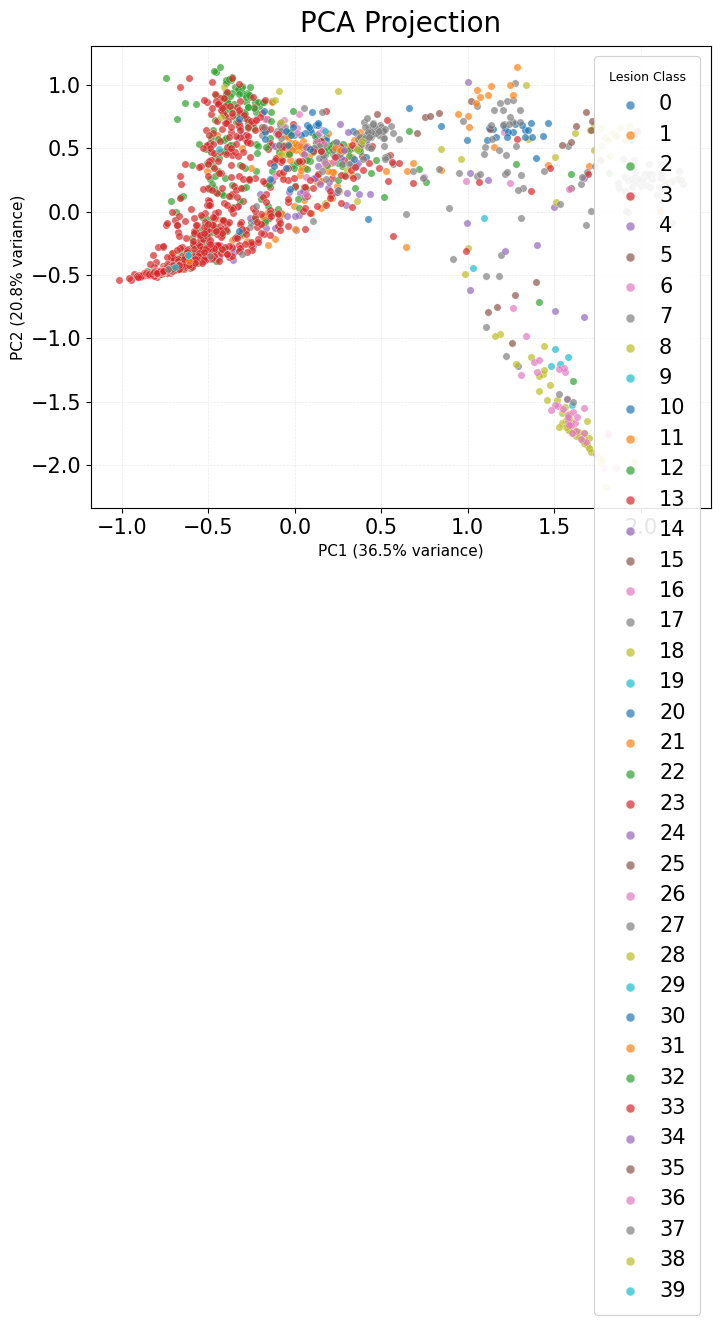

In [23]:
# [flat_labels[i] for i in clusters[1]]
import utils_external.plot_helper_visual as plot_helper_visual 
importlib.reload(plot_helper_visual)# Reload 
plot_pca_clusters = plot_helper_visual.plot_pca_clusters

import numpy as np
plot_pca_clusters (image_feats[keep], flat_labels[keep], name = None)

# labels['class_vector'].shape

In [168]:
flat_labels2 = torch.tensor(flat_labels2)

NameError: name 'flat_labels2' is not defined

In [47]:
torch.acosh(model.l_target.pow(2).sum(dim = -1).add(1).sqrt())
2*torch.atanh(z_p.pow(2).sum(dim =-1).sqrt())

tensor([2.3684, 2.5648, 2.6499, 2.3966, 2.6213, 2.3237, 2.4812, 2.5176, 2.6072,
        2.4068, 2.4101, 2.5975, 2.6316, 2.4332, 2.3468, 2.5356, 2.5422, 2.3371,
        2.6484, 2.4698, 2.3374, 2.5803, 2.5810, 2.4103, 2.5399, 2.4976, 2.3582,
        2.5311, 2.1807, 2.4797, 2.4663, 2.4646, 2.3551, 2.3713, 2.4599, 2.6351,
        2.4378, 2.2529, 2.6745, 2.3220, 1.8544, 1.8204, 1.9273, 1.8854, 1.8648,
        1.7934, 1.9196, 1.7926, 1.7496, 1.9070, 1.7970, 1.9014, 1.8834, 1.8500,
        1.7056, 1.2000, 1.2000, 1.2000, 1.2000, 1.2000, 0.0000])

In [24]:
import utils_external.classification_metrics as accuracy_mat
importlib.reload(accuracy_mat)
multiclass_metrics = accuracy_mat.multiclass_metrics
correct_wrong_indices = accuracy_mat.correct_wrong_indices
import utils_external.hierarchy_matrics as hierarchy 
importlib.reload(hierarchy)# Reload 
hierarchical_metrics = hierarchy.hierarchical_metrics # Extract the updated function from the reloaded module

In [25]:
oupt[1286:].norm(dim=-1).mean()

tensor(12.7839)

In [26]:
for i in range(9):
    class_mask = flat_labels.to(oupt.device).eq(i)
    class_lengths = image_feats[class_mask].norm(dim=-1)
    class_mean = class_lengths.mean()
    print(i, class_mean)

0 tensor(1.7671, device='cuda:0')
1 tensor(1.6980, device='cuda:0')
2 tensor(2.1927, device='cuda:0')
3 tensor(1.8617, device='cuda:0')
4 tensor(1.7679, device='cuda:0')
5 tensor(1.6703, device='cuda:0')
6 tensor(1.2346, device='cuda:0')
7 tensor(1.7240, device='cuda:0')
8 tensor(2.2062, device='cuda:0')


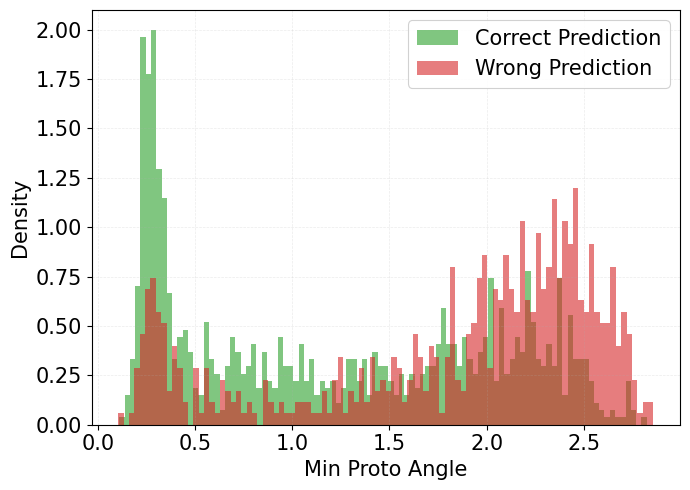

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

cls_wrong = correct_wrong_indices(image_logits[keep], flat_labels[keep])
wrong_idx = cls_wrong["wrong_sample_indices"].to(oupt.device)
correct_idx = cls_wrong["correct_sample_indices"].to(oupt.device)

wrong_length = angle_min.values[keep][wrong_idx]#.norm(dim=-1)
correct_length = angle_min.values[keep][correct_idx]#.norm(dim=-1)


# wrong_length = image_feats[keep][correct_idx].norm(dim=-1)
# correct_length = image_feats[keep][wrong_idx].norm(dim=-1)


# split = 1728

# wrong_keep = keep[:split]
# wrong_length = image_feats[:split][wrong_keep].norm(dim=-1)

# correct_keep = keep[split:]
# correct_length = image_feats[split:][correct_keep].norm(dim=-1)


wrong_values = wrong_length.detach().cpu().numpy()
correct_values = correct_length.detach().cpu().numpy()


plot_norm_dist(correct_values, wrong_values, "cor_wrong_derm12345_derm1m.svg")

Direction       : x1 <= threshold
AUROC           : 0.7131
Best threshold  : 1.809766
TPR             : 0.6857
FPR             : 0.3475
Youden's J      : 0.3383


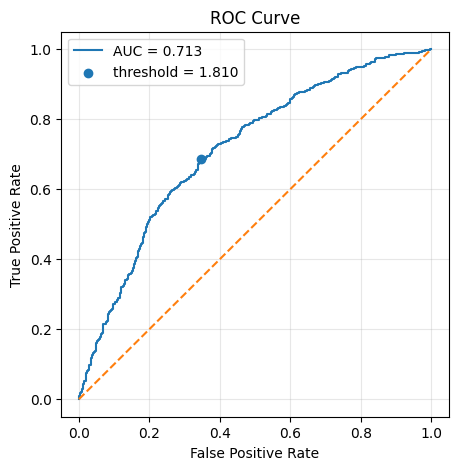

{'auc': 0.7131292465459322,
 'threshold': 1.809766,
 'direction': 'x1 <= threshold',
 'tpr': 0.6857429718875502,
 'fpr': 0.3474842767295597,
 'youden_j': 0.33825869515799045}

In [38]:
from utils_external.classification_metrics import roc_separation
roc_separation(correct_length, wrong_length)

In [36]:
def plot_norm_dist(correct, wrong, name="feature_norm_distribution.svg", bins=100):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(correct, bins=bins, density=True, alpha=0.6, color="tab:green", label="Correct Prediction")
    ax.hist(wrong, bins=bins, density=True, alpha=0.6, color="tab:red", label="Wrong Prediction")
    ax.set_xlabel(r"Min Proto Angle", fontsize=15)
    ax.set_ylabel("Density", fontsize=15)
    leg = ax.legend(loc="upper right", fontsize=15, frameon=True, framealpha=0.9)
    leg.get_frame().set_linewidth(0.8)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.25)
    ax.tick_params(axis="both", labelsize=15)
    plt.tight_layout()
    if name is not None:
        plt.savefig(name, format="svg", bbox_inches="tight")
    plt.show()

In [33]:
result = multiclass_metrics(image_logits[keep], flat_labels[keep],  topk = [4])
result

{'accuracy': 0.6102941176470589,
 'balanced_accuracy': 0.40944017529804033,
 'macro_f1': 0.3826225506467688,
 'weighted_f1': 0.5797652835095526,
 'classwise_f1': tensor([0.6667, 0.0000, 0.7068, 0.3692, 0.4286, 0.6154, 0.5714, 0.4615, 0.7115,
         0.0370, 0.7692, 0.3206, 0.5882, 0.0000, 0.0846, 0.0000, 0.4689, 0.6197,
         0.7692, 0.0000, 0.8636, 0.0000, 0.1880, 0.7484, 0.5000, 0.8000, 0.0000,
         0.4000, 0.1667, 0.0000, 0.3068, 0.5238, 0.6667, 0.0000, 0.0000, 0.0000,
         0.5977, 0.6486, 0.7059, 0.0000], dtype=torch.float64),
 'classwise_precision': tensor([0.7500, 0.0000, 0.6438, 0.6000, 0.7500, 0.6667, 0.5000, 1.0000, 0.7551,
         0.1111, 0.6818, 0.4176, 0.6122, 0.0000, 0.2727, 0.0000, 0.6154, 0.6875,
         0.7407, 0.0000, 0.8261, 0.0000, 0.2872, 0.7254, 1.0000, 1.0000, 0.0000,
         0.4000, 0.1667, 0.0000, 0.2727, 0.5238, 0.5000, 0.0000, 0.0000, 0.0000,
         0.5000, 0.7273, 0.6000, 0.0000], dtype=torch.float64),
 'classwise_recall': tensor([0.6000, 0.0

In [127]:
from Datasets.label_details import get_hierarchy
TREE, NODES, _ = get_hierarchy("derm12345") # milk10k, isic2019, derm12345

In [128]:
topk=3
h_metrics = hierarchical_metrics(
    output=image_logits[keep],       # [N, number_of_leaves]
    labels=flat_labels[keep],  # [N]
    tree=TREE,
    nodes=NODES,
    topk= topk,)

print(h_metrics["mistake_severity"])
print(h_metrics["hierarchical_distance_top_" + str(topk)])
print(h_metrics["accuracy_at_depth"]) # h_metrics.keys()

2.0404531955718994
1.202001690864563
{0: 1.0, 1: 0.9399510025978088, 2: 0.6660539507865906, 3: 0.6213235259056091}


In [48]:
# hyperbolic_umap_torch.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

EPS = 1e-6

# ---------------------------------------------------------
# Poincare disk utilities, curvature c = 1
# ---------------------------------------------------------
def project_ball(z, eps=1e-5):
    """
    Keep points inside unit Poincare disk.
    z: (..., 2)
    """
    norm = torch.norm(z, dim=-1, keepdim=True).clamp_min(EPS)
    max_norm = 1.0 - eps
    scale = torch.clamp(max_norm / norm, max=1.0)
    return z * scale


def poincare_dist(x, y, eps=1e-6):
    """
    Hyperbolic distance on Poincare disk.
    x, y: (..., 2)
    """
    x2 = (x * x).sum(dim=-1)
    y2 = (y * y).sum(dim=-1)
    diff2 = ((x - y) ** 2).sum(dim=-1)

    denom = (1.0 - x2).clamp_min(eps) * (1.0 - y2).clamp_min(eps)
    arg = 1.0 + 2.0 * diff2 / denom
    return torch.acosh(arg.clamp_min(1.0 + eps))
# ---------------------------------------------------------
# Build UMAP fuzzy graph from torch features
# ---------------------------------------------------------
@torch.no_grad()
def build_umap_graph_torch(features, n_neighbors=15, local_connectivity=1.0):
    """
    features: (B, D) torch tensor
    returns:
        edge_i, edge_j, edge_w
    """

    X = F.normalize(features.detach().float(), dim=1)
    B = X.shape[0]

    # Euclidean/cosine-style neighbor search.
    # For large B, replace this with FAISS.
    dist = torch.cdist(X, X)
    dist.fill_diagonal_(float("inf"))

    knn_dist, knn_idx = torch.topk(
        dist, k=n_neighbors, largest=False, dim=1
    )

    # UMAP smooth kNN distance approximation
    rho = knn_dist[:, 0]

    target = torch.log2(torch.tensor(float(n_neighbors), device=X.device))
    sigma = torch.ones(B, device=X.device)

    for i in range(B):
        lo, hi = 1e-3, 1000.0
        d_i = knn_dist[i] - rho[i]

        for _ in range(64):
            mid = (lo + hi) / 2.0
            psum = torch.exp(-torch.clamp(d_i, min=0.0) / mid).sum()

            if psum > target:
                hi = mid
            else:
                lo = mid

        sigma[i] = (lo + hi) / 2.0

    rows = torch.arange(B, device=X.device).repeat_interleave(n_neighbors)
    cols = knn_idx.reshape(-1)

    d = knn_dist.reshape(-1)
    r = rho.repeat_interleave(n_neighbors)
    s = sigma.repeat_interleave(n_neighbors)

    vals = torch.exp(-torch.clamp(d - r, min=0.0) / s.clamp_min(EPS))

    # Symmetrize fuzzy set:
    # w_ij + w_ji - w_ij*w_ji
    W = torch.zeros(B, B, device=X.device)
    W[rows, cols] = vals
    W_sym = W + W.T - W * W.T

    edge_i, edge_j = torch.where(W_sym > 0)
    edge_w = W_sym[edge_i, edge_j]

    # Remove self edges
    keep = edge_i != edge_j
    return edge_i[keep], edge_j[keep], edge_w[keep]


# ---------------------------------------------------------
# Hyperbolic UMAP model
# ---------------------------------------------------------

class HyperbolicUMAP(nn.Module):
    def __init__(self, n_points, init_scale=1e-3):
        super().__init__()
        self.z = nn.Parameter(init_scale * torch.randn(n_points, 2))

    def forward(self):
        return project_ball(self.z)


def hyperbolic_umap_loss(
    z,
    edge_i,
    edge_j,
    edge_w,
    n_neg=5,
    min_dist=0.1,
    spread=1.0,
):
    """
    Attractive fuzzy graph loss + negative sampling repulsion.
    """

    zi = z[edge_i]
    zj = z[edge_j]

    d_pos = poincare_dist(zi, zj)

    # UMAP-like attractive probability
    a = 1.0 / spread
    b = 1.0
    p_pos = 1.0 / (1.0 + a * (d_pos / min_dist.clamp_min(EPS)) ** (2 * b))

    loss_pos = -edge_w * torch.log(p_pos.clamp_min(EPS))
    loss_pos = loss_pos.mean()

    # Negative samples
    N = z.shape[0]
    neg_j = torch.randint(0, N, (edge_i.shape[0], n_neg), device=z.device)
    zi_neg = z[edge_i].unsqueeze(1)
    zj_neg = z[neg_j]

    d_neg = poincare_dist(zi_neg, zj_neg)

    p_neg = 1.0 / (1.0 + a * (d_neg / min_dist.clamp_min(EPS)) ** (2 * b))

    loss_neg = -torch.log((1.0 - p_neg).clamp_min(EPS)).mean()

    return loss_pos + loss_neg


# ---------------------------------------------------------
# Main function
# ---------------------------------------------------------

def fit_hyperbolic_umap(
    features,
    labels=None,
    n_neighbors=15,
    epochs=1000,
    lr=1e-2,
    n_neg=5,
    device=None,
):
    """
    features: torch.Tensor, shape (B, D)
    labels: torch.Tensor, shape (B,), optional
    returns:
        z: torch.Tensor, shape (B, 2), Poincare disk coordinates
    """

    if device is None:
        device = features.device

    features = features.to(device).float()
    B = features.shape[0]

    edge_i, edge_j, edge_w = build_umap_graph_torch(
        features,
        n_neighbors=n_neighbors,
    )

    model = HyperbolicUMAP(B).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    min_dist = torch.tensor(0.1, device=device)

    for epoch in range(epochs):
        opt.zero_grad()

        z = model()

        loss = hyperbolic_umap_loss(
            z,
            edge_i,
            edge_j,
            edge_w,
            n_neg=n_neg,
            min_dist=min_dist,
        )

        loss.backward()
        opt.step()

        with torch.no_grad():
            model.z.copy_(project_ball(model.z))

        if epoch % 100 == 0:
            print(f"epoch {epoch:04d} | loss={loss.item():.4f}")

    return model().detach().cpu()


# ---------------------------------------------------------
# Visualization
# ---------------------------------------------------------

def plot_poincare_disk(z, labels=None, title="Hyperbolic UMAP"):
    z = z.detach().cpu()

    plt.figure(figsize=(7, 7))

    circle = plt.Circle((0, 0), 1.0, fill=False, linewidth=2)
    ax = plt.gca()
    ax.add_patch(circle)

    if labels is None:
        plt.scatter(z[:, 0], z[:, 1], s=12)
    else:
        labels = labels.detach().cpu()
        plt.scatter(z[:, 0], z[:, 1], c=labels, s=12, cmap="tab20")

    plt.xlim(-1.05, 1.05)
    plt.ylim(-1.05, 1.05)
    plt.gca().set_aspect("equal")
    plt.title(title)
    plt.xlabel("Poincare x")
    plt.ylabel("Poincare y")
    plt.show()

epoch 0000 | loss=6.9254
epoch 0100 | loss=3.1467
epoch 0200 | loss=1.0153
epoch 0300 | loss=0.7386
epoch 0400 | loss=0.5745
epoch 0500 | loss=0.4502
epoch 0600 | loss=0.3955
epoch 0700 | loss=0.3809
epoch 0800 | loss=0.3782
epoch 0900 | loss=0.3790


ValueError: 'c' argument has 1 elements, which is inconsistent with 'x' and 'y' with size 4816.

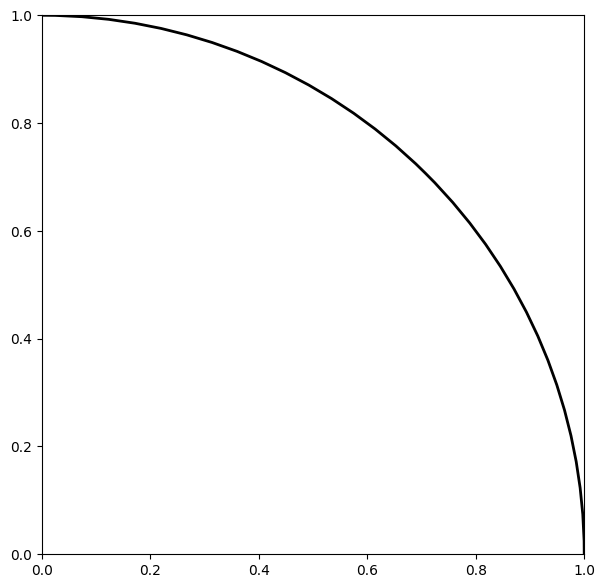

In [49]:
z = fit_hyperbolic_umap(
    # MC.lorentz_to_poincare(MC.spatial_to_lorentz(L.exp_map0(x))),
    MC.lorentz_to_poincare(MC.spatial_to_lorentz(L.exp_map0(image_feats))),
    labels=flat_labels.argmax(-1),
    n_neighbors=15,
    epochs=1000,
    lr=1e-1,
    n_neg=5,
)

plot_poincare_disk(z, flat_labels.argmax(-1))

In [67]:
import torch
import numpy as np
import umap
import matplotlib.pyplot as plt


def hypstructure_style_hyperbolic_umap(features, labels=None,
                                       n_neighbors=15,
                                       min_dist=0.1,
                                       metric="cosine",
                                       scale=1.0):
    """
    features: torch.Tensor or np.ndarray, shape (N, D)
    labels:   torch.Tensor or np.ndarray, shape (N,)
    """

    if torch.is_tensor(features):
        X = features.detach().cpu().float().numpy()
    else:
        X = np.asarray(features, dtype=np.float32)

    z_euc = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        metric=metric,
        random_state=0,
    ).fit_transform(X)

    z_euc = torch.tensor(z_euc, dtype=torch.float32)

    # Normalize before expmap so points do not all saturate near boundary
    z_euc = z_euc - z_euc.mean(dim=0, keepdim=True)
    z_euc = scale * z_euc / (z_euc.std(dim=0, keepdim=True) + 1e-6)

    # Poincare expmap at origin, same form as their geom/poincare.py
    norm = z_euc.norm(dim=-1, keepdim=True).clamp_min(1e-15)
    z_hyp = torch.tanh(norm) * z_euc / norm

    z_hyp = z_hyp.detach().cpu().numpy()

    fig, ax = plt.subplots(figsize=(7, 7))
    circle = plt.Circle((0, 0), 1.0, fill=False, linewidth=2)
    ax.add_patch(circle)

    if labels is None:
        ax.scatter(z_hyp[:, 0], z_hyp[:, 1], s=8)
    else:
        if torch.is_tensor(labels):
            labels = labels.detach().cpu().numpy()
        ax.scatter(z_hyp[:, 0], z_hyp[:, 1], c=labels, s=8, cmap="tab20")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.show()

    return torch.tensor(z_hyp)

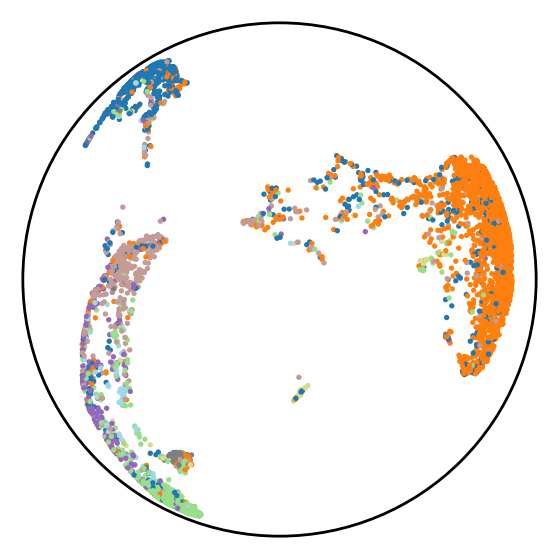

tensor([[ 0.7180,  0.3738],
        [ 0.3756,  0.4173],
        [-0.3384, -0.9094],
        ...,
        [-0.3693, -0.9039],
        [ 0.8541, -0.0136],
        [-0.6738, -0.5664]])

In [68]:
hypstructure_style_hyperbolic_umap(oupt[keep], labels=flat_labels[keep],
                                       n_neighbors=15,
                                       min_dist=0.1,
                                       metric="cosine",
                                       scale=1.0) # comes much better! 

In [89]:
one_hot_labels = F.one_hot(flat_labels.long(), num_classes= 40)

In [90]:
# similiarity svcca, mutual information. 
# code source https://github.com/minyoungg/platonic-rep/blob/main/metrics.py
from utils_external.metrics_platonic import AlignmentMetrics
# flat_labels = torch.stack(flat_labels, dim = 0)
print(AlignmentMetrics.svcca(image_feats[keep], one_hot_labels.float()[keep], 7)) # or  flat_labels = one_hot.float() 
# alternative svcca metrics https://github.com/google/svcca/blob/master/cca_core.py

import numpy as np

# the following NP version generate almost identical np mean

# from utils_external.cca_core import get_cca_similarity
# b1= np.array(x).T
# b2 = np.array(flat_labels).T
# cb1 = b1 - np.mean(b1, axis=0, keepdims=True)
# cb2 = b2 - np.mean(b2, axis=0, keepdims=True)
# Ub1, sb1, Vb1 = np.linalg.svd(cb1, full_matrices=False)
# Ub2, sb2, Vb2 = np.linalg.svd(cb2, full_matrices=False)
# component = 6
# svb1 = np.dot(sb1[:component]*np.eye(component), Vb1[:component])
# svb2 = np.dot(sb2[:component]*np.eye(component), Vb2[:component])
# svcca_results = get_cca_similarity(svb1, svb2, epsilon=1e-10, verbose=False)
# plt.plot(svcca_results["cca_coef1"], lw=2.0, label="SAM")
# plt.xlabel("Sorted CCA Correlation Coeff Idx")
# plt.grid()
# np.mean(svcca_results["cca_coef1"]) ## almost identical to the AlignmentMetrics.svcca(x, flat_labels, components)
# one_hot_labels_rand = one_hot_labels[torch.randperm(one_hot_labels.size(0), device=one_hot_labels.device)] # randomization

0.2688154255880401


In [94]:
# sample wise similarity
import utils_external.adjacency_matrix as mat_sim

euc_adj = mat_sim.euclidean_adj(x, dist_ = 2, tau = 0.5)
mani_adj = mat_sim.manifold_dist_adj(euc_adj, alpha= 0.7)

In [95]:
euc_adj.shape

torch.Size([1312, 1312])

In [105]:
d_point = 9
idx_m = mat_sim.get_topk_neighbors(mani_adj, d_point, 50)
idx_e = mat_sim.get_topk_neighbors(euc_adj, d_point, 50)

In [106]:
print((flat_labels[idx_m] == flat_labels[d_point]).all(dim= -1).sum())
print((flat_labels[idx_e] == flat_labels[d_point]).all(dim= -1).sum())

tensor(3)
tensor(4)


In [107]:
flat_labels[d_point].argmax()

tensor(8)

In [108]:
torch.where(flat_labels.argmax(-1) == 7)

(tensor([   6,   21,   35,   74,   84,  105,  129,  133,  135,  148,  155,  175,
          191,  209,  212,  242,  255,  265,  284,  290,  338,  357,  379,  386,
          397,  406,  450,  459,  465,  478,  487,  498,  510,  541,  552,  562,
          563,  569,  579,  602,  604,  607,  618,  626,  627,  635,  637,  647,
          660,  666,  682,  684,  704,  707,  714,  727,  730,  742,  751,  755,
          771,  779,  787,  789,  805,  832,  853,  855,  859,  864,  865,  876,
          878,  896,  897,  933,  941,  950,  976,  981,  996, 1007, 1035, 1036,
         1048, 1056, 1084, 1095, 1106, 1120, 1121, 1130, 1144, 1163, 1206, 1209,
         1230, 1234, 1237, 1238, 1246, 1295, 1310]),)

In [109]:
common = []
for i in idx:
    if i in idx2:
        common.append(int(i))

NameError: name 'idx2' is not defined

In [111]:
(flat_labels[torch.tensor(common)] == flat_labels[d_point]).all(dim= -1).sum()

IndexError: tensors used as indices must be long, int, byte or bool tensors

In [34]:
cls_attn = attn[:, :, 0, 1:]   # [B, 12, 196]
cls_attn = cls_attn.mean(dim=1) # dino attention mask
# cls_attn = cls_attn[3] # individual mask [image number]
B = cls_attn.shape[0]
mask = cls_attn.reshape(B, 14, 14)
attn.shape

torch.Size([32, 12, 197, 197])

In [30]:
mask =  mask ** 0.5

In [20]:
cls_attn.shape

torch.Size([32, 196])

In [38]:
# image points connection 
image_feats = tokens[:, 1:, :] # bs, no_feats (196), feat_dim 

def cosine_affinity(features: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Args:    features: [B, N, D]
    Returns: affinity: [B, N, N]
    """
    features = F.normalize(features, p=2, dim=-1, eps=eps)
    # [B, N, D] @ [B, D, N] -> [B, N, N]
    affinity = torch.bmm(features, features.transpose(1, 2))
    affinity = (affinity+ 1)/2
    return affinity

def exponential_affinity(
    features: torch.Tensor, temperature: float = 1.0,
    eps: float = 1e-6) -> torch.Tensor:
    """
    Args:        features: [B, N, D]
    Returns:        affinity: [B, N, N]
    """
    # Pairwise Euclidean distances: [B, N, N]
    distances = torch.cdist(features, features, p=2)
    # affinity = 1.0 / (1.0 + distances)    # Stable inverse-distance similarity
    affinity = torch.exp(-distances / temperature) # RBF affinity
    return affinity

features = image_feats 

affinity_cosine = cosine_affinity(features)
# affinity_cosine = exponential_affinity(features, 3)

print(affinity_cosine.shape)

torch.Size([32, 196, 196])


In [39]:
import torch
from utils_external.spec_clus_ng import spectral_cluster


labels = spectral_cluster(
    affinity_cosine,   # [B, 196, 196]
    n_clusters= 3
)

print(labels.shape)
mask = labels.reshape(B, 14, 14).float()
# [B, 196]

torch.Size([32, 196])


In [40]:
mask = F.interpolate(
    mask.unsqueeze(1),      # [B,1,14,14]
    size=(224,224),
    mode='bilinear',
    align_corners=False
).float()

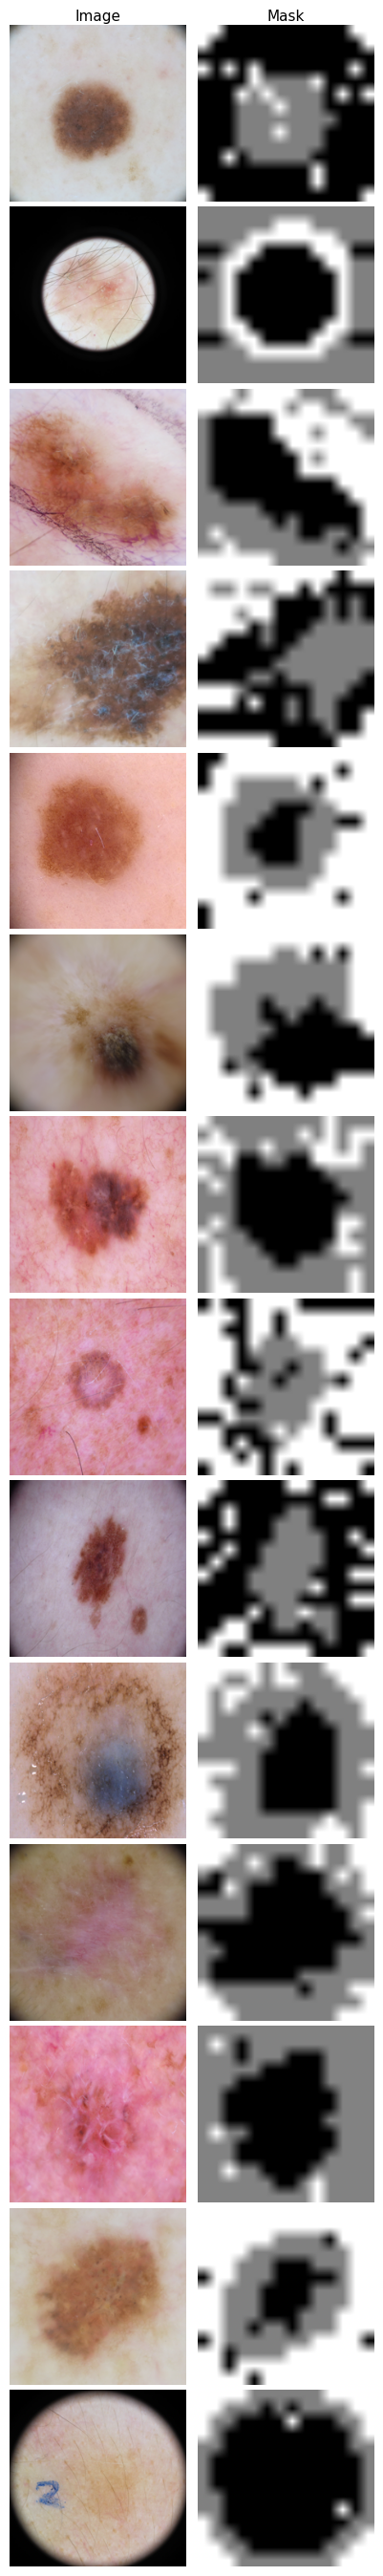

In [41]:
import matplotlib.pyplot as plt

n = 14

fig, axes = plt.subplots(
    n,
    2,
    figsize=(4, 2 * n),
    gridspec_kw={
        "wspace": 0.01,
        "hspace": 0.03
    }
)

for i in range(n):
    img = type_image[i].detach().permute(1, 2, 0).cpu()
    mask_img = mask[i, 0].detach().cpu()
    
    axes[i, 0].imshow(img)
    axes[i, 1].imshow(mask_img, cmap="gray")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

# Only one pair of headings
axes[0, 0].set_title("Image", fontsize=11, pad=3)
axes[0, 1].set_title("Mask", fontsize=11, pad=3)

plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.96,
    bottom=0.01,
    wspace=0.01,
    hspace=0.03
)

plt.savefig(
    "../Figures_Saved/isic2019_derm1m_FT_cluster.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.01
)

plt.show()

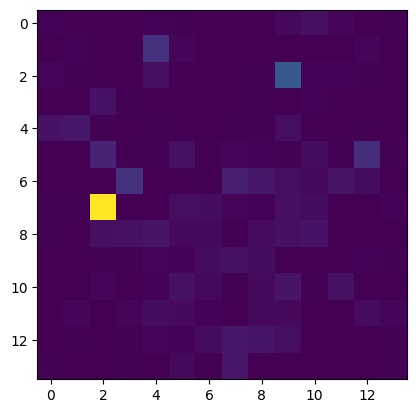

In [75]:
cls_attn = attn[:, :, 0, 1:]
cls_attn = cls_attn[:,0,:]
B = cls_attn.shape[0]
mask1 = cls_attn.reshape(B, 14, 14)
bs_pos = 3
plt.imshow(mask1[bs_pos])

In [96]:
from transformers import pipeline

pipe = pipeline("feature-extraction", model="dmis-lab/biobert-v1.1")

config.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/433M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/433M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [32]:
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("dmis-lab/biobert-v1.1")
model = AutoModel.from_pretrained("dmis-lab/biobert-v1.1")

config.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/433M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/433M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [33]:
model.embeddings

BertEmbeddings(
  (word_embeddings): Embedding(28996, 768, padding_idx=0)
  (position_embeddings): Embedding(512, 768)
  (token_type_embeddings): Embedding(2, 768)
  (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

In [34]:
from Datasets import label_details
mlk_label = label_details.milk10k_label_tree

In [38]:
milk_classes = [mlk_label[i]['name'] for i in mlk_label.keys()]
milk_classes

['Basal cell carcinoma',
 'Melanocytic nevus',
 'Benign keratinocytic lesion',
 'Squamous cell carcinoma / keratoacanthoma',
 'Melanoma',
 'Actinic keratosis / intraepidermal carcinoma',
 'Dermatofibroma',
 'Inflammatory and infectious',
 'Vascular lesions and hemorrhage',
 'Other benign proliferations / collision',
 'Other malignant proliferations / collision']

In [32]:
l_oupt = L.log_map0(oupt)
L.pairwise_dist(oupt, oupt).shape
dists.shape

torch.Size([900, 900])

In [91]:
# Gromov hyperbolicity test
def delta_hyp_torch(dismat):
    p = 0
    row = dismat[p, :][None, :]
    col = dismat[:, p][:, None]
    XY_p = 0.5 * (row + col - dismat)
    maxmin = torch.minimum(XY_p[:, :, None], XY_p[None, :, :]).max(1).values
    return (maxmin - XY_p).max()
import numpy as np

idx = np.random.choice(len(oupt), 1000)
# all_features_small = oupt[idx]

all_features_small = image_feats_h[idx]
# Euclidean distance similarity
# dists = torch.cdist(all_features_small, all_features_small)

# Lorentz distance similarity
dists = L.pairwise_dist(all_features_small, all_features_small)

delta = delta_hyp_torch(dists)
diam = torch.max(dists)
del_rel =  2*delta/diam
print('delta relative: ', del_rel)
c = (0.144 / del_rel) ** 2
print('c value: ', c)


delta relative:  tensor(0.1950, device='cuda:0')
c value:  tensor(0.5455, device='cuda:0')


In [55]:
# label tree experimentations.
PAD_CLASSNAMES = [
    "nevus",
    "basal cell carcinoma",
    "actinic keratosis",
    "seborrheic keratosis",
    "squamous cell carcinoma",
    "melanoma"
]

# Build text prompts
template = lambda c: f'This is a skin image of {c}'
text =  tokenizer([template(c) for c in milk_classes])


In [56]:
import torch.nn.functional as F
with torch.no_grad(), torch.autocast("cuda"):
    # Encode image and text
    text_features = F.normalize(model.encode_text(text))

/usr/local/lib/python3.11/dist-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(


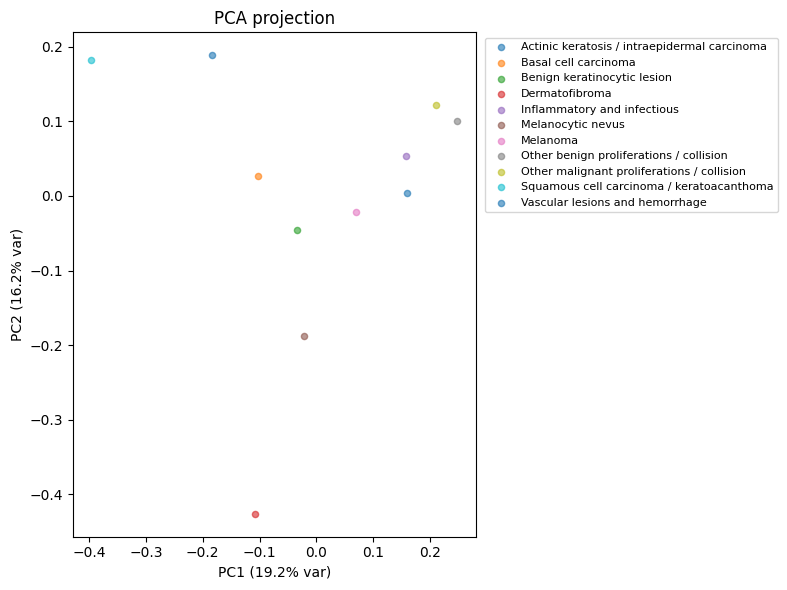

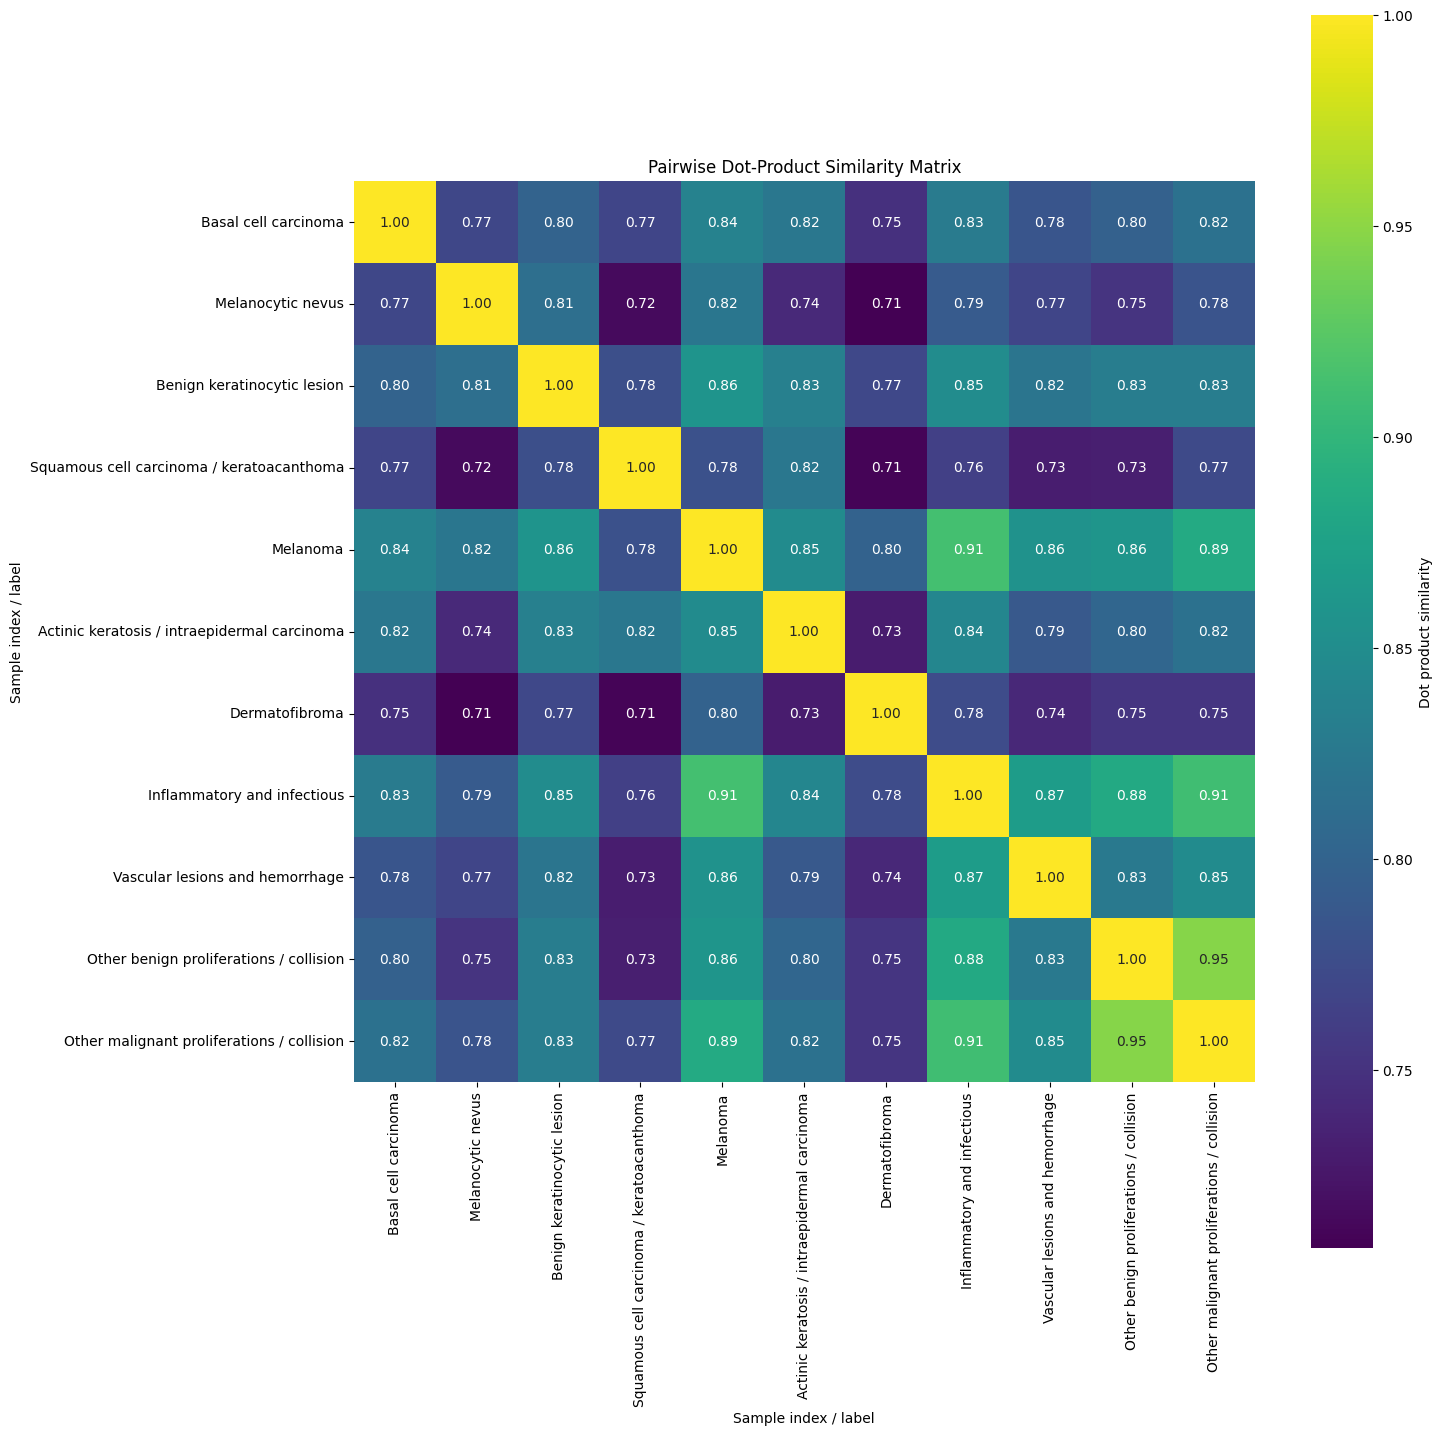

tensor([[1.0000, 0.7698, 0.8003, 0.7679, 0.8365, 0.8237, 0.7486, 0.8285, 0.7848,
         0.7979, 0.8168],
        [0.7698, 1.0000, 0.8135, 0.7154, 0.8225, 0.7418, 0.7078, 0.7910, 0.7679,
         0.7515, 0.7842],
        [0.8003, 0.8135, 1.0000, 0.7784, 0.8589, 0.8336, 0.7716, 0.8484, 0.8218,
         0.8307, 0.8303],
        [0.7679, 0.7154, 0.7784, 1.0000, 0.7802, 0.8242, 0.7102, 0.7629, 0.7314,
         0.7325, 0.7734],
        [0.8365, 0.8225, 0.8589, 0.7802, 1.0000, 0.8478, 0.7983, 0.9128, 0.8568,
         0.8599, 0.8855],
        [0.8237, 0.7418, 0.8336, 0.8242, 0.8478, 1.0000, 0.7307, 0.8417, 0.7880,
         0.8029, 0.8169],
        [0.7486, 0.7078, 0.7716, 0.7102, 0.7983, 0.7307, 1.0000, 0.7751, 0.7407,
         0.7528, 0.7525],
        [0.8285, 0.7910, 0.8484, 0.7629, 0.9128, 0.8417, 0.7751, 1.0000, 0.8680,
         0.8841, 0.9105],
        [0.7848, 0.7679, 0.8218, 0.7314, 0.8568, 0.7880, 0.7407, 0.8680, 1.0000,
         0.8258, 0.8477],
        [0.7979, 0.7515, 0.8307, 0.73

In [57]:
text_features @ text_features.T
plot_pca_clusters(text_features, milk_classes)
plot_similarity_matrix(text_features, milk_classes)

In [52]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

def plot_similarity_matrix(features, labels):
    """
    Compute pairwise dot‑product similarity matrix from features and plot it
    in confusion matrix style using the provided labels.

    Args:
        features (torch.Tensor): Tensor of shape (bs, D), where bs is batch size
                                 and D is feature dimension.
        labels (list): List of length bs, containing labels/names for the samples.
                       Used for both x and y tick labels.
    Returns:
        torch.Tensor: The similarity matrix of shape (bs, bs).
    """
    # Ensure features is a torch tensor
    if not isinstance(features, torch.Tensor):
        features = torch.tensor(features, dtype=torch.float32)

    # Compute dot product similarity: (bs, bs)
    sim_matrix = features @ features.T

    # Convert to numpy for plotting
    sim_np = sim_matrix.detach().cpu().numpy()

    # Create heatmap
    plt.figure(figsize=(15, 15))
    sns.heatmap(sim_np,
                annot=True,          # show numeric values in cells
                fmt=".2f",
                xticklabels=labels,
                yticklabels=labels,
                cmap="viridis",      # change to 'coolwarm', 'Blues', etc. if desired
                square=True,
                cbar_kws={"label": "Dot product similarity"})

    plt.title("Pairwise Dot‑Product Similarity Matrix")
    plt.xlabel("Sample index / label")
    plt.ylabel("Sample index / label")
    plt.tight_layout()
    plt.show()

    return sim_matrix




In [36]:
# getting the model
import script.custom_models.derm1M_custom_classifier
import importlib
importlib.reload(script.custom_models.derm1M_custom_classifier)
from script.custom_models.derm1M_custom_classifier import DermLIPWithHead, DermLIPWithHypHead

In [37]:
# delete it later
results = torch.load("../Datasets/sarkar_embeddings_milk10k.pt")
z_p = results["data"]  # torch.Tensor
z_l = MC.poincare_to_lorentz(z_p) # lorentz points
# data loader 
z_l[:,1:].shape

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = DermLIPWithHypHead(32, z_l[0:11,1:].to(device)) # lorentz space components
model_2 = model.to(device)

/scratch/24874665/ipykernel_2980313/2670444179.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  results = torch.load("../Datasets/sarkar_embeddings_milk10k.pt")


In [ ]:
with torch.no_grad():
    _a, _d, _ah = L.oxy_angle_dist(l_output['output'], model.l_target.to(device), labels['class_index'].to(device), min_radius= 1)
    # _ac, _dc, _ahc = L.oxy_dist_angle_no_label(l_output['output'], model.l_target.to(device))
    _scale = model.logit_scale.exp()
    ce_loss = nn.functional.cross_entropy(_scale * (-_d), labels['class_index'].to(device))
    entailment_loss = torch.clamp(_a - _ah, min=0).mean()

In [ ]:
# model manual checking 
model_2 = DermLIPWithHead(11)
with torch.no_grad():
    o = model_2(input_image, labels['class_vector'])
lf = nn.CrossEntropyLoss()
lf(o['output'], labels['class_vector'])

In [55]:
# optimizer Settings

model = model_2 #.to(device)

# Define parameter groups
import torch.optim as optim
from torch.optim.lr_scheduler import LambdaLR
import math

lr1 = 1e-5   # lower lr for pretrained ViT backbone
lr2 = 1e-4   # higher lr for classification head

param_groups = []
all_params = list(model.parameters())
added_params = set()

def add_params(mod, lr):
    for p in mod.parameters():
        if p not in added_params:
            param_groups.append({"params": [p], "lr": lr})
            added_params.add(p)
        
# Custom groups
if hasattr(model, "visual"):
    add_params(model.visual, lr1)

if hasattr(model, "clf_head"):
    add_params(model.clf_head, lr2)

# Add any remaining parameters not covered
for p in model.parameters():
    if p not in added_params:
        param_groups.append({"params": [p], "lr": lr1})

# optimizer = optim.SGD(param_groups, momentum=0.9, weight_decay=1e-4)
optimizer = optim.AdamW(param_groups, weight_decay=1e-4)  # AdamW is standard for ViT


# Optional sanity check
covered = sum(p.numel() for g in optimizer.param_groups for p in g["params"])
total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Covered parameters: {covered}/{total} ({covered/total:.2%})")

# Optional: list groups and learning rates
# for i, g in enumerate(optimizer.param_groups):
#     print(f"Group {i}: lr={g['lr']}, num_params={len(g['params'])}")


# Warmup + Cosine Decay Scheduler
warmup_epochs = 5
total_epochs = 50

def lr_lambda(current_epoch):
    if current_epoch < warmup_epochs:
        # Linear warmup
        return current_epoch / max(1, warmup_epochs)
    else:
        # Cosine decay after warmup
        progress = (current_epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = LambdaLR(optimizer, lr_lambda=lr_lambda)


# In training loop:
# optimizer.step()
# scheduler.step()  # call once per epoch

✅ Covered parameters: 86218379/86067083 (100.18%)


In [57]:
device = 'cpu'

In [58]:
# training Loop

import random
import pdb
im_size = 224

zero_shot = False
un_l = [3,5,13,19]  # unlabeled class indices


for epoch in range(1):  # loop over the dataset multiple times    
    running_loss = 0.0

        
    for i, data in enumerate(train_loader, 0):
        
        # data loading starts
        
        orig_image, orig_label = data
        
        if dataset_keep_track == "MILK 10K datasets":
            images = orig_image['clinical_closeup']
            labels = orig_label['class_vector'].float() # euclidean one
            labels = orig_label['class_index'] #hyperbolic one
            
        elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets']:
            type_image = images
        
        images = _augmentation_gpu(images.float(), augmentation_num = random.randint(0, 2), im_size = im_size)
        input_image = dl_preprocess(images/255.0)
        
        # data loading ends
        
        optimizer.zero_grad()
    
        outputs = model(input_image.to(device), labels.to(device))           # outputs is a dict
        loss = outputs["loss"]
        
        if torch.isnan(loss):
            print(f"[NaN Detected] Epoch {epoch} Step {step}")
            print("Logging:", outputs.get("logging", {}))
            pdb.set_trace()   # drop into debugger

        loss.backward()
        optimizer.step()
        scheduler.step() 
        
        
        print(loss)
        
        break
        
        

tensor(2.6249, dtype=torch.float64, grad_fn=<AddBackward0>)
